In [1]:
#!/usr/bin/env python3
"""The first code cell of every notebook a job may run — copied byte for byte.

One question, answered once: WHERE IS THE REPOSITORY THIS NOTEBOOK RUNS
AGAINST. Every later cell reads `ROOT` and none of them asks again.

Opened by a person on their own machine, this answers it exactly the way
these notebooks always have. A notebook lives at `<repo>/<Name>/Notebooks/`,
so the repository is two directories above the working directory. Nothing was
handed over, nothing is checked, and the behaviour is unchanged.

Started by a runner on a remote worker, it does not answer it by looking
around. The runner exports the directory it cloned the pinned commit into and
the commit it pinned; this cell reads both, and PROVES the checkout is at that
commit before returning it.

Guessing is the whole reason this cell exists. Under the runner the kernel's
working directory is the runner's own and the clone sits one level inside it,
so two directories up is two levels ABOVE the working directory — a directory
that EXISTS on any worker. The path resolves, the insert succeeds, and the run
dies later with a missing module naming a package, never with the wrong root.
The one fact worth having is the one the failure never mentions.

Three refusals, and each one is a refusal rather than a fallback because this
is the path that spends metered quota:

- **Half a handoff** — one variable present and the other missing. Something
  built this environment and got it half right; that is precisely the state a
  fallback cannot tell apart from a laptop, and the fallback resolves a
  directory that exists everywhere.
- **A root that is not a checkout** — the declared directory is missing, or
  holds no readable `HEAD`. There is nothing to compare against, and an
  unproven root is what this cell was written to stop being acceptable.
- **A checkout at a different commit** — the declared commit and the one on
  disk disagree. A job that runs the wrong commit RUNS: it returns numbers
  shaped exactly like the right ones, and nothing downstream can tell.

Absent means LOCAL. It never means "work it out".

Importable and independently testable, the way the runner's own two cells
are: every function is pure and takes its environment and its working
directory as arguments, and only the last line — the binding a notebook cell
exists to perform — reads the real ones.
"""
import os
from pathlib import Path

#: The directory a runner cloned the pinned commit into. Forge-owned and
#: deliberately generic: this is the contract between a runner and the
#: notebook it starts, not a name borrowed from any one repository.
CLONE_ROOT_ENV = "FORGE_CLONE_ROOT"

#: The commit that clone was pinned to, exported beside it so this cell can
#: check rather than trust. A root on its own would only move the guess one
#: step: a directory handed over is still a directory nobody proved.
CLONE_COMMIT_ENV = "FORGE_CLONE_COMMIT"

#: How far above a notebook's own directory the repository sits when nobody
#: hands anything over: `<repo>/<Name>/Notebooks` -> `<repo>`.
LOCAL_ROOT_DEPTH = 1


def head_commit(root):
    """The commit `root`'s `HEAD` names, read straight out of `.git`.

    No subprocess, deliberately. A notebook cell that shells out needs a git
    binary on a worker's PATH that nothing here declared, and every checker
    that reads these notebooks then has to decide whether running the cell is
    safe — a cell that binds the repository is the last one that may be
    skipped for that reason.

    A pinned checkout is detached: the runner fetches a commit and checks out
    what it fetched, never a branch, so `HEAD` holds the raw commit and this
    is a one-line read. A symbolic `HEAD` is resolved anyway — through the
    loose ref and then `packed-refs` — so pointing these variables at an
    ordinary checkout gets an answer instead of a refusal that would be about
    the file format rather than about the commit.

    Returns `None` when there is nothing to read. The caller turns that into
    a refusal; this function never decides.
    """
    git = Path(root) / ".git"
    if git.is_file():
        pointer = git.read_text(encoding="utf-8").strip()
        if not pointer.startswith("gitdir:"):
            return None
        git = Path(root) / pointer[len("gitdir:"):].strip()
    if not git.is_dir():
        return None
    head = git / "HEAD"
    if not head.is_file():
        return None
    text = head.read_text(encoding="utf-8").strip()
    if not text.startswith("ref:"):
        return text or None
    ref = text[len("ref:"):].strip()
    loose = git / ref
    if loose.is_file():
        return loose.read_text(encoding="utf-8").strip() or None
    packed = git / "packed-refs"
    if packed.is_file():
        for line in packed.read_text(encoding="utf-8").splitlines():
            if line.startswith("#") or line.startswith("^"):
                continue
            fields = line.split()
            if len(fields) == 2 and fields[1] == ref:
                return fields[0]
    return None


def resolve_repository_root(environ=None, cwd=None, head_reader=head_commit):
    """The repository this notebook runs against, or a refusal saying why.

    `environ` and `cwd` are arguments so the whole decision can be driven
    without a kernel, a clone or a worker; the binding at the bottom of this
    cell passes the real ones.
    """
    environ = os.environ if environ is None else environ
    here = Path.cwd() if cwd is None else Path(cwd)
    declared_root = environ.get(CLONE_ROOT_ENV)
    declared_commit = environ.get(CLONE_COMMIT_ENV)

    if not declared_root and not declared_commit:
        return here.parents[LOCAL_ROOT_DEPTH]

    if not declared_root or not declared_commit:
        raise RuntimeError(
            "half a handoff: {0}={1!r} and {2}={3!r}. Both name the pinned "
            "checkout this notebook must run against, and one without the "
            "other is an environment somebody built and got half right. "
            "Falling back to the local layout here would resolve a directory "
            "that exists on any machine and is not this repository.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))

    root = Path(declared_root)
    found = head_reader(root) if root.is_dir() else None
    if found is None:
        raise RuntimeError(
            "{0}={1!r} is not a readable checkout: no commit could be read "
            "from its HEAD. {2} declares {3!r}, and there is nothing here to "
            "check it against.".format(
                CLONE_ROOT_ENV, declared_root,
                CLONE_COMMIT_ENV, declared_commit))
    if found.lower() != declared_commit.lower():
        raise RuntimeError(
            "the checkout at {0}={1!r} is at commit {2}, and {3} declares "
            "{4}. A job that runs a commit nobody asked for RUNS, and the "
            "numbers it returns look exactly like the right ones.".format(
                CLONE_ROOT_ENV, declared_root, found,
                CLONE_COMMIT_ENV, declared_commit))
    return root


ROOT = resolve_repository_root()


# BALLADEER — 01. Inventario

Plan experimental v02 (`experiments-plan-experimental-mil-creda-sobre-balladeer-v02.md`), secciones 1, 3.2 y 10.1. Antes de auditar un solo registro hay que saber qué registros existen y de quién son. Este cuaderno recorre el árbol del release **sin abrir ningún archivo de datos** (solo nombres y tamaños) y lee `users_demographics.json`, que es la fuente de la etiqueta.

Toda la lógica vive en `src/MIL_CREDA_EEG/inventory.py`; este cuaderno solo la corre y la muestra.

In [2]:
# El repositorio lo resolvió la celda de arriba; ésta sólo lo usa.
import sys
import json

REPOSITORY = ROOT
sys.path.insert(0, str(REPOSITORY / "src"))

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

from MIL_CREDA_EEG import audit_plots, inventory, modality

%matplotlib inline
pd.set_option("display.width", 160)

RAW = REPOSITORY / inventory.RAW_RELATIVE
OUT = REPOSITORY / "MIL-CREDA" / "Results" / "audit"
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)

print("intérprete:", sys.executable)
assert str(REPOSITORY / ".venv") in sys.executable, "el kernel no es el venv del repositorio"
print("datos:     ", RAW.relative_to(REPOSITORY))


intérprete: /Users/diego/Proyectos/papersmith-ai/implementations/Domain_Adaptation/.venv/bin/python
datos:      MIL-CREDA/Data/raw/BALLADEER ADHD DATASET


## 1. Qué hay en disco

Una fila por archivo de sesión. Los `.DS_Store` del Finder se ignoran.

In [3]:
index = inventory.build_index(RAW)
index.to_csv(OUT / "inventory.csv", index=False)
eeg = inventory.eeg_records(index)
eeg.to_csv(OUT / "eeg_records.csv", index=False)
demo = inventory.load_demographics(RAW)
demo.to_csv(OUT / "demographics.csv", index=False)

print("sujetos (carpetas UB*):", index["subject"].nunique())
print("archivos de sesión:    ", len(index))
print("registros EEG:         ", len(eeg))
print("tamaño EEG (GB):       ", round(eeg["size_bytes"].sum() / 1e9, 1))
kinds = index["kind"].value_counts()
kinds

sujetos (carpetas UB*): 158
archivos de sesión:     1441
registros EEG:          683
tamaño EEG (GB):        62.0


kind
EEG             683
TAGS            459
GAME_DATA       154
EYE_TRACKING    145
Name: count, dtype: int64

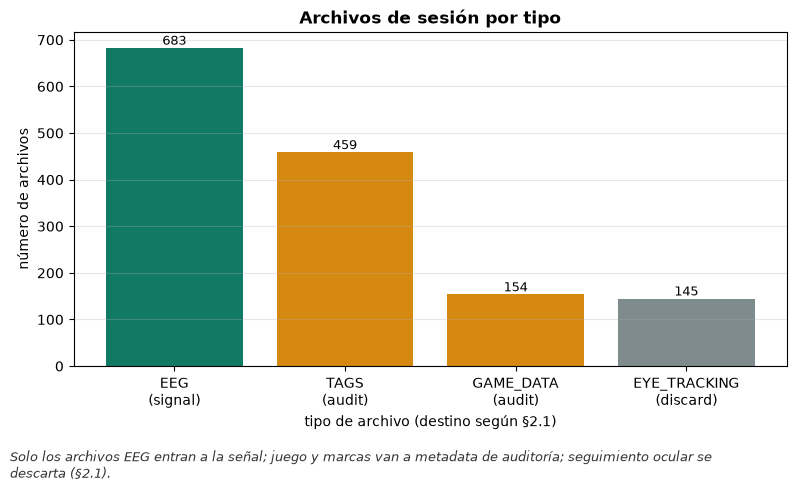

In [4]:
destino = {k: modality.classify_file(k)[0] for k in kinds.index}
colores = {"signal": "#117a65", "audit": "#d68910", "discard": "#7f8c8d"}
fig = audit_plots.bar(
    kinds.rename(lambda k: f"{k}\n({destino[k]})"),
    "Archivos de sesión por tipo", "tipo de archivo (destino según §2.1)", "número de archivos",
    "Solo los archivos EEG entran a la señal; juego y marcas van a metadata de auditoría; "
    "seguimiento ocular se descarta (§2.1).",
    colors=[colores.get(destino[k], "#555") for k in kinds.index])
audit_plots.save(fig, "01_archivos_por_tipo", FIG); plt.show()

## 2. Sujetos por tarea y dispositivo, contra la Tabla 1 del data paper

La Tabla 1 del data paper cuenta participantes con al menos un registro válido por tarea y dispositivo. Acá se cuenta lo que hay en disco; la diferencia es lo primero que hay que mirar.

In [5]:
per = inventory.subjects_per_condition(eeg)
rows = []
for (task, device), paper in inventory.DATA_PAPER_TABLE1.items():
    disk = int(per.loc[task, device]) if task in per.index and device in per.columns else 0
    rows.append({"tarea": task, "dispositivo": device, "en disco": disk, "data paper": paper,
                 "diferencia": disk - paper})
table1 = pd.DataFrame(rows)
table1.to_csv(OUT / "table1_vs_data_paper.csv", index=False)
print(per)
table1

device         CGX  EPOCPLUS  EPOCX
task_label                         
Cognifit         0        59     72
Robots           0        59     73
Slackline-L1   140         0      0
Slackline-L11  140         0      0
Slackline-L6   140         0      0


,tarea,dispositivo,en disco,data paper,diferencia
0,Slackline-L1,CGX,140,140,0
1,Slackline-L6,CGX,140,140,0
2,Slackline-L11,CGX,140,140,0
3,Robots,EPOCPLUS,59,59,0
4,Robots,EPOCX,73,73,0
5,Cognifit,EPOCPLUS,59,59,0
6,Cognifit,EPOCX,72,70,2


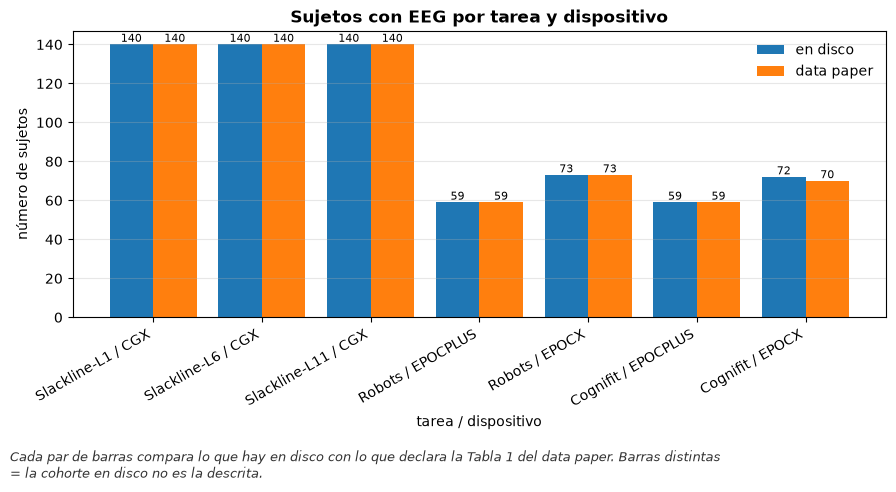

In [6]:
plot = table1.assign(cond=table1["tarea"] + " / " + table1["dispositivo"]).set_index("cond")[["en disco", "data paper"]]
fig = audit_plots.grouped_bar(plot, "Sujetos con EEG por tarea y dispositivo",
    "tarea / dispositivo", "número de sujetos",
    "Cada par de barras compara lo que hay en disco con lo que declara la Tabla 1 del data paper. "
    "Barras distintas = la cohorte en disco no es la descrita.")
audit_plots.save(fig, "01_sujetos_vs_tabla1", FIG); plt.show()

## 3. Demografía y etiqueta

La etiqueta es `diagnosed` (sí / no / indeterminado). `group` es la asignación del equipo de psicólogos y se conserva aparte: el cruce de abajo muestra que no coinciden.

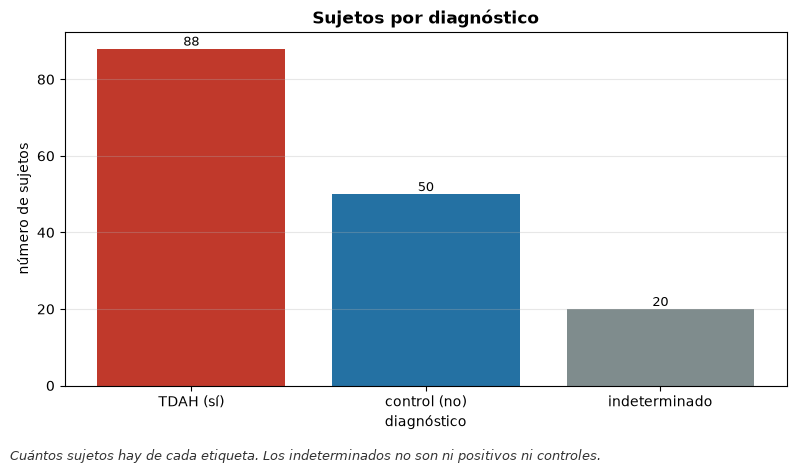

indeterminados: {'count': 20, 'by_group': {'2': 20}, 'by_sex': {'F': 13, 'M': 7}}


In [7]:
labels = demo["label"].value_counts().reindex(["yes", "no", "undetermined"])
fig = audit_plots.bar(labels.rename(audit_plots.LABEL_ES), "Sujetos por diagnóstico",
    "diagnóstico", "número de sujetos",
    "Cuántos sujetos hay de cada etiqueta. Los indeterminados no son ni positivos ni controles.",
    colors=[audit_plots.PALETTE[k] for k in labels.index])
audit_plots.save(fig, "01_sujetos_por_diagnostico", FIG); plt.show()
und = inventory.indeterminate_summary(demo)
print("indeterminados:", und)

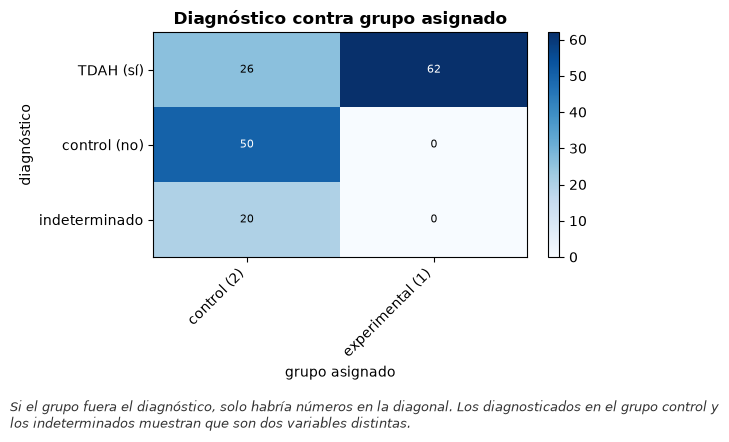

group,control (2),experimental (1)
label,,
TDAH (sí),26,62
control (no),50,0
indeterminado,20,0


In [8]:
cross = pd.crosstab(demo["label"].map(audit_plots.LABEL_ES), demo["group"].map({1: "experimental (1)", 2: "control (2)"}))
fig = audit_plots.heatmap(cross, "Diagnóstico contra grupo asignado", "grupo asignado", "diagnóstico",
    "Si el grupo fuera el diagnóstico, solo habría números en la diagonal. Los diagnosticados en el "
    "grupo control y los indeterminados muestran que son dos variables distintas.", figsize=(6, 4))
audit_plots.save(fig, "01_diagnostico_vs_grupo", FIG); plt.show()
cross

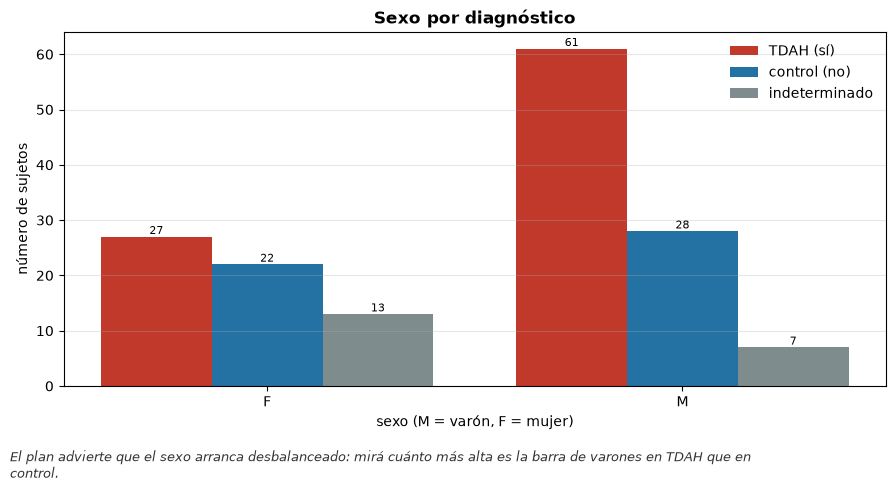

label   yes    no  undetermined
sex                            
F      0.31  0.44          0.65
M      0.69  0.56          0.35


In [9]:
sex = pd.crosstab(demo["sex"], demo["label"])[["yes", "no", "undetermined"]]
fig = audit_plots.grouped_bar(sex, "Sexo por diagnóstico", "sexo (M = varón, F = mujer)", "número de sujetos",
    "El plan advierte que el sexo arranca desbalanceado: mirá cuánto más alta es la barra de varones en TDAH que en control.")
audit_plots.save(fig, "01_sexo_por_diagnostico", FIG); plt.show()
print((sex / sex.sum()).round(2))

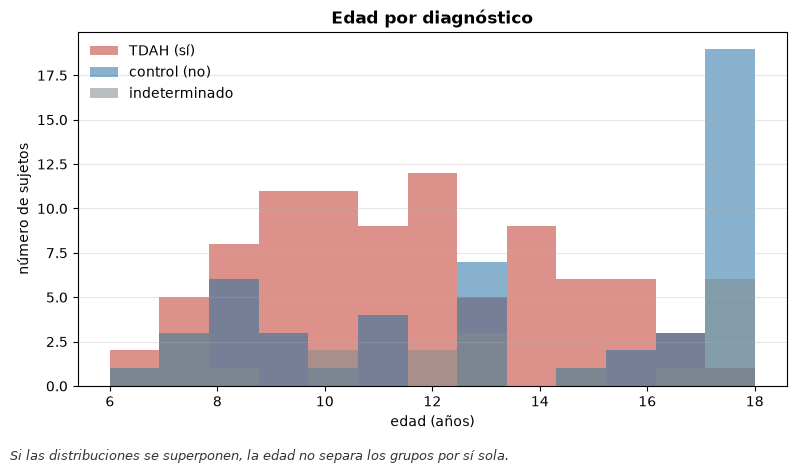

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
no,50.0,13.740000,4.280044,6.0,9.25,14.0,18.0,18.0
undetermined,20.0,12.900000,4.423621,6.0,9.50,13.0,18.0,18.0
yes,88.0,11.465909,2.943721,6.0,9.00,11.0,14.0,18.0


In [10]:
fig = audit_plots.hist(None, "Edad por diagnóstico", "edad (años)", "número de sujetos",
    "Si las distribuciones se superponen, la edad no separa los grupos por sí sola.",
    bins=13, groups={k: demo.loc[demo["label"] == k, "age"] for k in ["yes", "no", "undetermined"]})
audit_plots.save(fig, "01_edad_por_diagnostico", FIG); plt.show()
demo.groupby("label")["age"].describe()

## 4. Registros por sujeto y condición

Una condición es tarea + nivel + familia de dispositivo (§3.2). Si un sujeto tuviera más de un registro en una misma condición, la bolsa necesitaría una regla que el plan no tiene.

pares sujeto-condición: 683
con más de un registro: 0
sujetos Emotiv con los dos modelos: 1


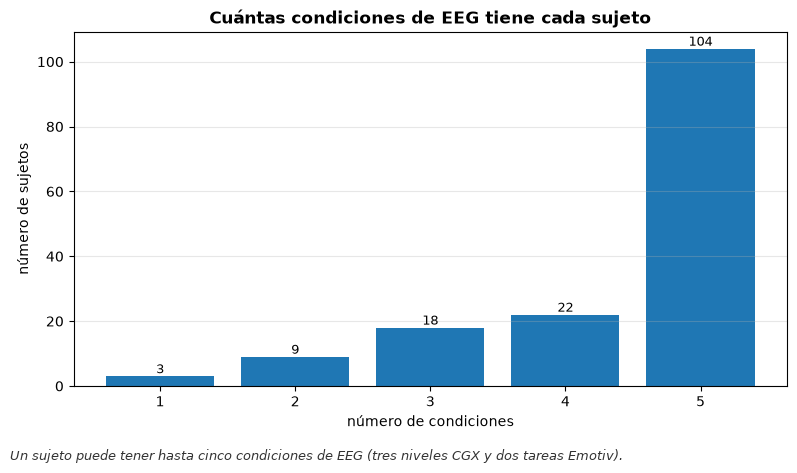

In [11]:
per_subject = eeg.groupby(["subject", "condition"]).size()
print("pares sujeto-condición:", len(per_subject))
print("con más de un registro:", int((per_subject > 1).sum()))
models = eeg[eeg["family"] == "EMOTIV"].groupby("subject")["device"].nunique()
print("sujetos Emotiv con los dos modelos:", int((models > 1).sum()))
counts = eeg.groupby("subject")["condition"].nunique().value_counts().sort_index()
fig = audit_plots.bar(counts, "Cuántas condiciones de EEG tiene cada sujeto", "número de condiciones",
    "número de sujetos", "Un sujeto puede tener hasta cinco condiciones de EEG (tres niveles CGX y dos tareas Emotiv).")
audit_plots.save(fig, "01_condiciones_por_sujeto", FIG); plt.show()

## 5. Solapamiento de sujetos entre condiciones (§10.1)

Decide el tamaño de cada partición disjunta por sujeto: un sujeto que está en las dos condiciones de una transferencia solo puede ir a uno de los dos dominios.

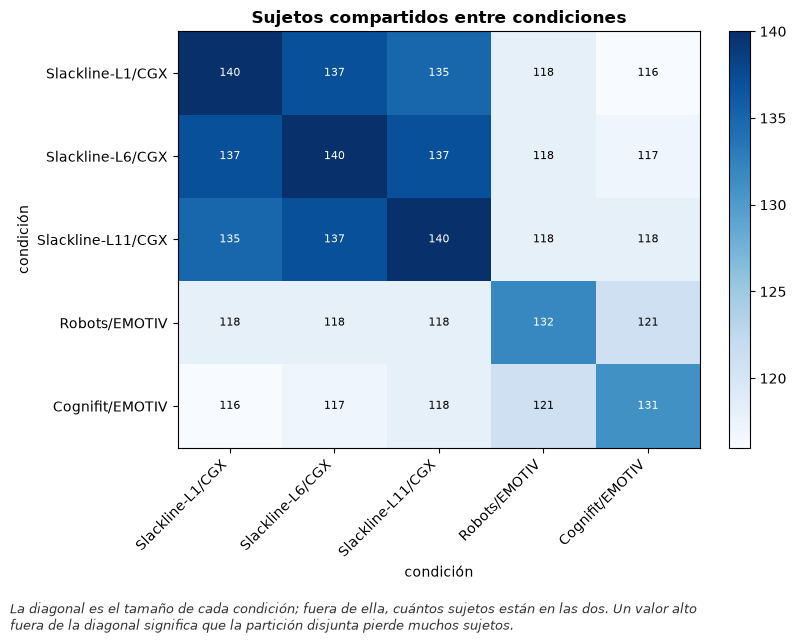

sujetos con EEG en las dos familias: 131 | solo CGX: 14 | solo Emotiv: 11
sujetos sin ningún registro EEG: ['UB0108', 'UB0112']
sujetos con las cinco condiciones: 104


In [12]:
overlap = inventory.condition_overlap(eeg)
order = [c for c in ["Slackline-L1/CGX", "Slackline-L6/CGX", "Slackline-L11/CGX", "Robots/EMOTIV", "Cognifit/EMOTIV"] if c in overlap.index]
overlap = overlap.loc[order, order]
overlap.to_csv(OUT / "condition_overlap.csv")
fig = audit_plots.heatmap(overlap, "Sujetos compartidos entre condiciones", "condición", "condición",
    "La diagonal es el tamaño de cada condición; fuera de ella, cuántos sujetos están en las dos. "
    "Un valor alto fuera de la diagonal significa que la partición disjunta pierde muchos sujetos.")
audit_plots.save(fig, "01_solapamiento_condiciones", FIG); plt.show()
fam = eeg.groupby("subject")["family"].agg(set)
both = fam.map(lambda s: s == {"CGX", "EMOTIV"})
print("sujetos con EEG en las dos familias:", int(both.sum()),
      "| solo CGX:", int(fam.map(lambda s: s == {"CGX"}).sum()),
      "| solo Emotiv:", int(fam.map(lambda s: s == {"EMOTIV"}).sum()))
print("sujetos sin ningún registro EEG:", sorted(set(demo["subject"]) - set(eeg["subject"])))
print("sujetos con las cinco condiciones:", int((eeg.groupby("subject")["condition"].nunique() == 5).sum()))

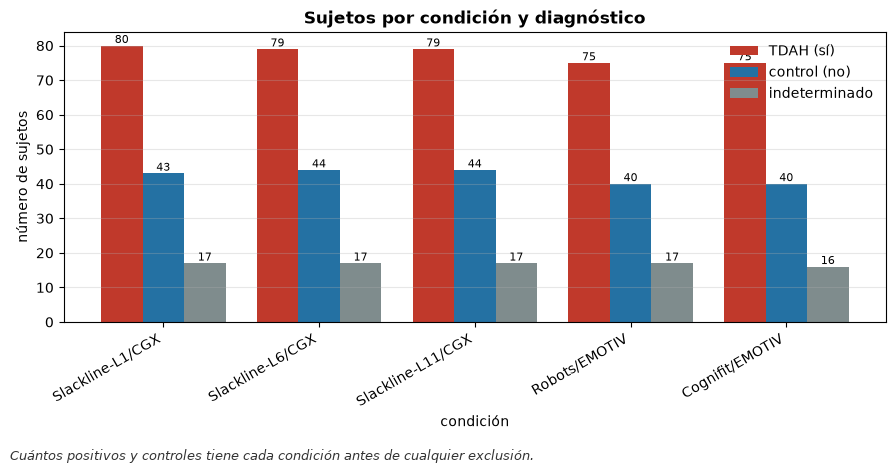

subject,yes,no,undetermined
Slackline-L1/CGX,80,43,17
Slackline-L6/CGX,79,44,17
Slackline-L11/CGX,79,44,17
Robots/EMOTIV,75,40,17
Cognifit/EMOTIV,75,40,16


In [13]:
lab = demo.set_index("subject")["label"]
by_label = pd.DataFrame({c: eeg[eeg["condition"] == c]["subject"].drop_duplicates().map(lab).value_counts()
                         for c in order}).T.reindex(columns=["yes", "no", "undetermined"]).fillna(0).astype(int)
by_label.to_csv(OUT / "condition_by_label.csv")
fig = audit_plots.grouped_bar(by_label, "Sujetos por condición y diagnóstico", "condición", "número de sujetos",
    "Cuántos positivos y controles tiene cada condición antes de cualquier exclusión.")
audit_plots.save(fig, "01_condicion_por_diagnostico", FIG); plt.show()
by_label